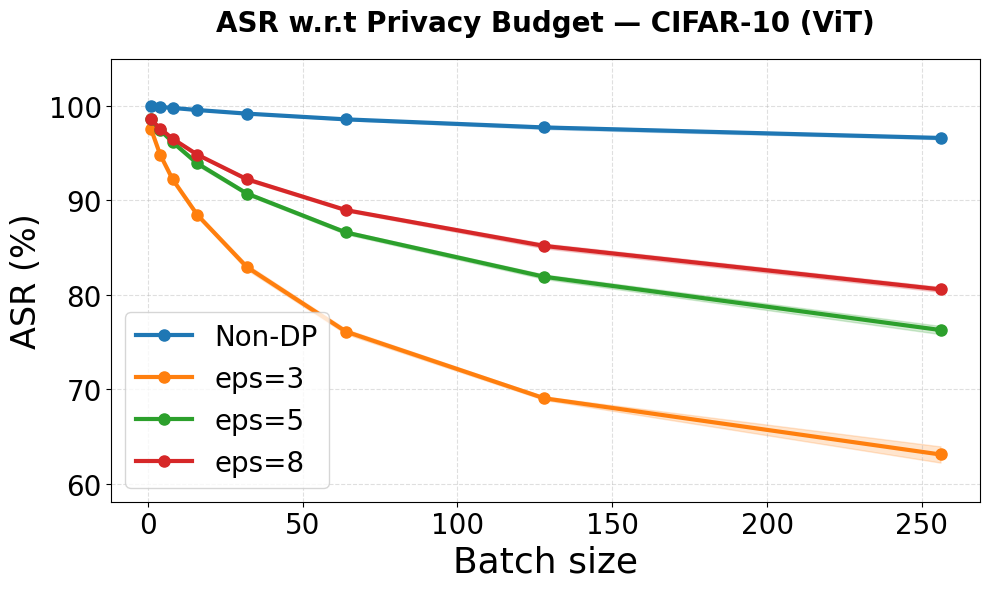

In [3]:
def plot_metric_with_std(df, mean_col, std_col, ylabel, title, marker="o"):
    plt.figure(figsize=(10, 6))
    
    # Define settings to maintain order
    settings = ["Non-DP", "eps=3", "eps=5", "eps=8"]
    
    for setting in settings:
        sub = df[df["Setting"] == setting]
        if sub.empty:
            continue
        
        # Plot the mean line
        # We capture the line object to reuse its color for the fill area
        line, = plt.plot(
            sub["Batch size"],
            sub[mean_col],
            marker=marker,
            linewidth=3,      # Slightly thicker for better visibility
            markersize=8,
            label=setting,
        )
        
        # Fill the area for standard deviation
        plt.fill_between(
            sub["Batch size"],
            sub[mean_col] - sub[std_col],
            sub[mean_col] + sub[std_col],
            color=line.get_color(),
            alpha=0.2          # Transparency of the fill
        )

    plt.xlabel("Batch size", fontsize=26)
    plt.ylabel(ylabel, fontsize=24) # Increased for readability
    plt.title(title, fontsize=20, weight="bold", pad=20)
    
    # Move legend to a clear spot if needed
    plt.legend(fontsize=20, frameon=True, loc='best')
    
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    
    # Optional: Increase the y-axis range slightly to prevent clipping of the fill
    plt.ylim(df[mean_col].min() - 5, 105) 

    plt.tight_layout()
    plt.show()

# Execute the plot
plot_metric_with_std(
    agg,
    mean_col="ASR_mean",
    std_col="ASR_std",
    ylabel="ASR (%)",
    title="ASR w.r.t Privacy Budget — CIFAR-10 (ViT)",
)

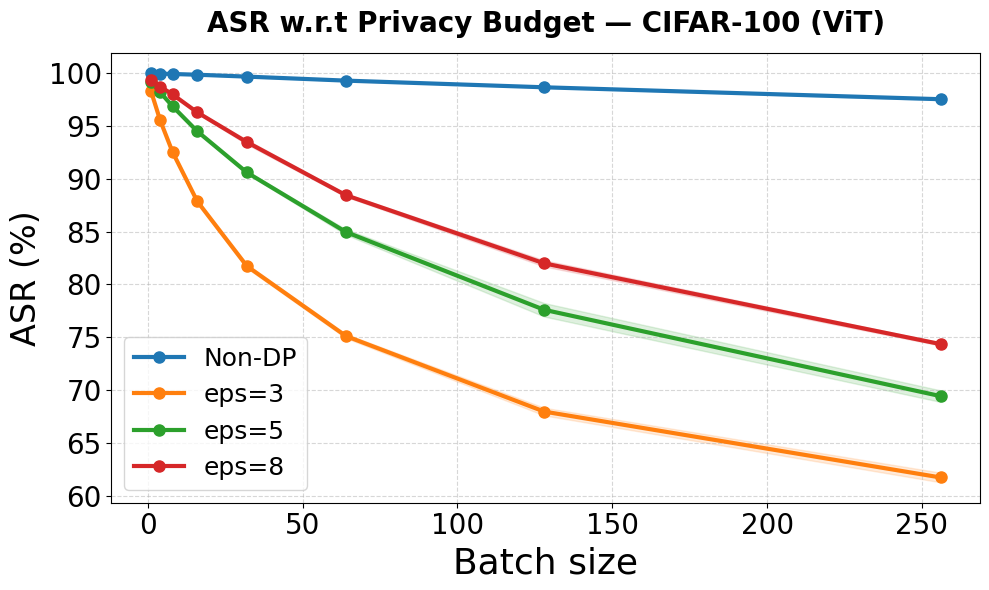

    Batch size Setting  ASR_mean   ASR_std  Adv_mean   Adv_std
0            1  Non-DP    99.999  0.002236    99.998  0.004472
1            1   eps=3    98.346  0.088487    96.692  0.176975
2            1   eps=5    99.182  0.080436    98.364  0.160873
3            1   eps=8    99.406  0.042924    98.812  0.085849
4            4  Non-DP    99.976  0.012450    99.952  0.024900
5            4   eps=3    95.542  0.053221    91.084  0.106442
6            4   eps=5    98.200  0.062048    96.400  0.124097
7            4   eps=8    98.748  0.096540    97.496  0.193080
8            8  Non-DP    99.934  0.017103    99.868  0.034205
9            8   eps=3    92.537  0.246161    85.074  0.492321
10           8   eps=5    96.875  0.171501    93.750  0.343001
11           8   eps=8    97.998  0.105451    95.996  0.210903
12          16  Non-DP    99.864  0.029665    99.728  0.059330
13          16   eps=3    87.859  0.144196    75.718  0.288392
14          16   eps=5    94.501  0.061583    89.002  0

In [4]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Setup global font for high-quality export
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# Files configuration
files = {
    "Non-DP": "/home/quannm/code/icml_promptmia/result_log/cifar100_vit_stealth.txt",
    "eps=3": "/home/quannm/code/icml_promptmia/result_log/cifar100_vit_eps3_stealth.txt",
    "eps=5": "/home/quannm/code/icml_promptmia/result_log/cifar100_vit_eps5_stealth.txt",
    "eps=8": "/home/quannm/code/icml_promptmia/result_log/cifar100_vit_eps8_stealth.txt",
}

pattern = re.compile(
    r"mia batch size:\s*(\d+).*?TPR:\s*([\d.]+)%.*?TNR:\s*([\d.]+)%.*?Advantage:\s*([\d.]+)%",
    re.DOTALL
)

rows = []

for setting, path in files.items():
    try:
        text = Path(path).read_text(errors="ignore")
        matches = pattern.findall(text)
        for bs, tpr, tnr, adv in matches:
            asr = (float(tpr) + float(tnr)) / 2.0
            rows.append((int(bs), setting, float(adv), asr))
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")

df = pd.DataFrame(rows, columns=["Batch size", "Setting", "Adv", "ASR"])
df = df[df["Batch size"] <= 256]

# Aggregate metrics
agg = (
    df.groupby(["Batch size", "Setting"])
      .agg(
          ASR_mean=("ASR", "mean"),
          ASR_std=("ASR", "std"),
          Adv_mean=("Adv", "mean"),
          Adv_std=("Adv", "std"),
      )
      .reset_index()
      .sort_values("Batch size")
)

def plot_metric_with_fill(df, mean_col, std_col, ylabel, title, marker="o"):
    plt.figure(figsize=(10, 6))
    settings = ["Non-DP", "eps=3", "eps=5", "eps=8"]
    
    for setting in settings:
        sub = df[df["Setting"] == setting]
        if sub.empty:
            continue
            
        # Plot the primary line
        line, = plt.plot(
            sub["Batch size"],
            sub[mean_col],
            marker=marker,
            linewidth=3,
            markersize=8,
            label=setting
        )
        
        # Fill standard deviation area
        plt.fill_between(
            sub["Batch size"],
            sub[mean_col] - sub[std_col],
            sub[mean_col] + sub[std_col],
            color=line.get_color(),
            alpha=0.15  # Soft transparency
        )

    plt.xlabel("Batch size", fontsize=26)
    plt.ylabel(ylabel, fontsize=24)
    plt.title(title, fontsize=20, weight="bold", pad=15)
    plt.legend(fontsize=18, loc='best', frameon=True)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    plt.tight_layout()
    plt.show()

# Generate the plot for CIFAR-100
plot_metric_with_fill(
    agg,
    mean_col="ASR_mean",
    std_col="ASR_std",
    ylabel="ASR (%)",
    title="ASR w.r.t Privacy Budget — CIFAR-100 (ViT)",
)

print(agg)

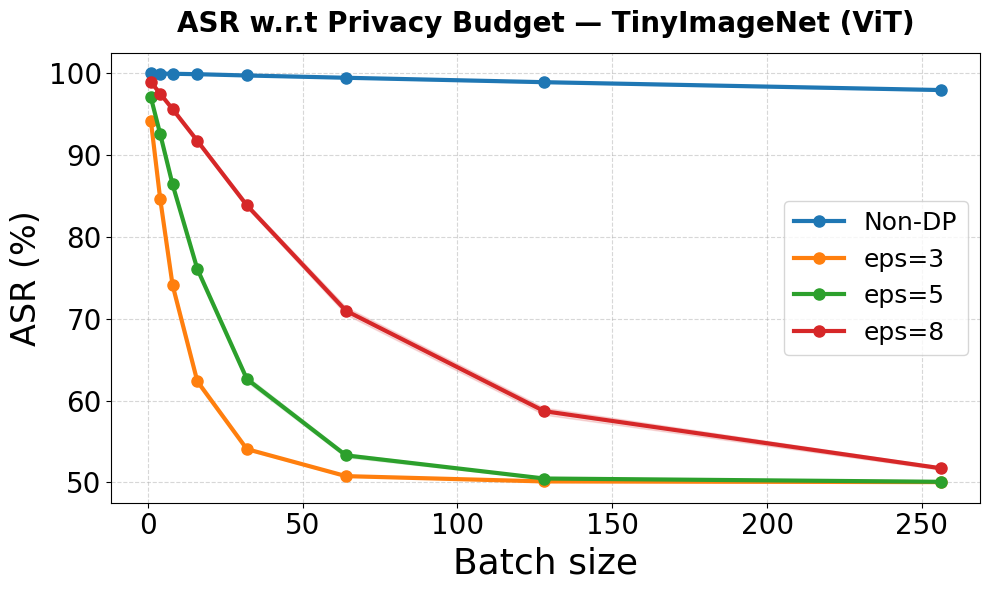

    Batch size Setting  ASR_mean   ASR_std  Adv_mean   Adv_std
0            1  Non-DP   99.9990  0.002236    99.998  0.004472
1            1   eps=3   94.1750  0.060553    88.350  0.121106
2            1   eps=5   97.0425  0.109125    94.085  0.218251
3            1   eps=8   98.9450  0.082614    97.890  0.165227
4            4  Non-DP   99.9670  0.006708    99.934  0.013416
5            4   eps=3   84.6690  0.348432    69.338  0.696864
6            4   eps=5   92.5900  0.151534    85.180  0.303068
7            4   eps=8   97.5080  0.114543    95.016  0.229085
8            8  Non-DP   99.9440  0.012942    99.888  0.025884
9            8   eps=3   74.1230  0.432212    48.246  0.864425
10           8   eps=5   86.4220  0.277840    72.844  0.555680
11           8   eps=8   95.6280  0.242348    91.256  0.484696
12          16  Non-DP   99.8900  0.028940    99.780  0.057879
13          16   eps=3   62.3520  0.347448    24.704  0.694896
14          16   eps=5   76.0810  0.204982    52.162  0

In [5]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Files configuration
files = {
    "Non-DP": "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_vit_stealth.txt",
    "eps=3": "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_vit_eps3_stealth.txt",
    "eps=5": "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_vit_eps5_stealth.txt",
    "eps=8": "/home/quannm/code/icml_promptmia/result_log/tinyimagenet_vit_eps8_stealth.txt",
}

pattern = re.compile(
    r"mia batch size:\s*(\d+).*?TPR:\s*([\d.]+)%.*?TNR:\s*([\d.]+)%.*?Advantage:\s*([\d.]+)%",
    re.DOTALL
)

rows = []

for setting, path in files.items():
    try:
        text = Path(path).read_text(errors="ignore")
        matches = pattern.findall(text)
        for bs, tpr, tnr, adv in matches:
            asr = (float(tpr) + float(tnr)) / 2.0
            rows.append((int(bs), setting, float(adv), asr))
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")

df = pd.DataFrame(rows, columns=["Batch size", "Setting", "Adv", "ASR"])
df = df[df["Batch size"] <= 256]

# Aggregate metrics
agg = (
    df.groupby(["Batch size", "Setting"])
      .agg(
          ASR_mean=("ASR", "mean"),
          ASR_std=("ASR", "std"),
          Adv_mean=("Adv", "mean"),
          Adv_std=("Adv", "std"),
      )
      .reset_index()
      .sort_values("Batch size")
)

def plot_metric_with_fill(df, mean_col, std_col, ylabel, title, marker="o"):
    plt.figure(figsize=(10, 6))
    settings = ["Non-DP", "eps=3", "eps=5", "eps=8"]
    
    for setting in settings:
        sub = df[df["Setting"] == setting]
        if sub.empty:
            continue
            
        # Plot the primary line
        line, = plt.plot(
            sub["Batch size"],
            sub[mean_col],
            marker=marker,
            linewidth=3,
            markersize=8,
            label=setting
        )
        
        # Shaded area for standard deviation
        # fill_between handles the 'fill-in' effect
        plt.fill_between(
            sub["Batch size"],
            sub[mean_col] - sub[std_col],
            sub[mean_col] + sub[std_col],
            color=line.get_color(),
            alpha=0.15  # Transparency level
        )

    plt.xlabel("Batch size", fontsize=26)
    plt.ylabel(ylabel, fontsize=24)
    plt.title(title, fontsize=20, weight="bold", pad=15)
    plt.legend(fontsize=18, loc='best', frameon=True)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    plt.tight_layout()
    plt.show()

# Generate the plot for TinyImageNet
plot_metric_with_fill(
    agg,
    mean_col="ASR_mean",
    std_col="ASR_std",
    ylabel="ASR (%)",
    title="ASR w.r.t Privacy Budget — TinyImageNet (ViT)",
)

print(agg)

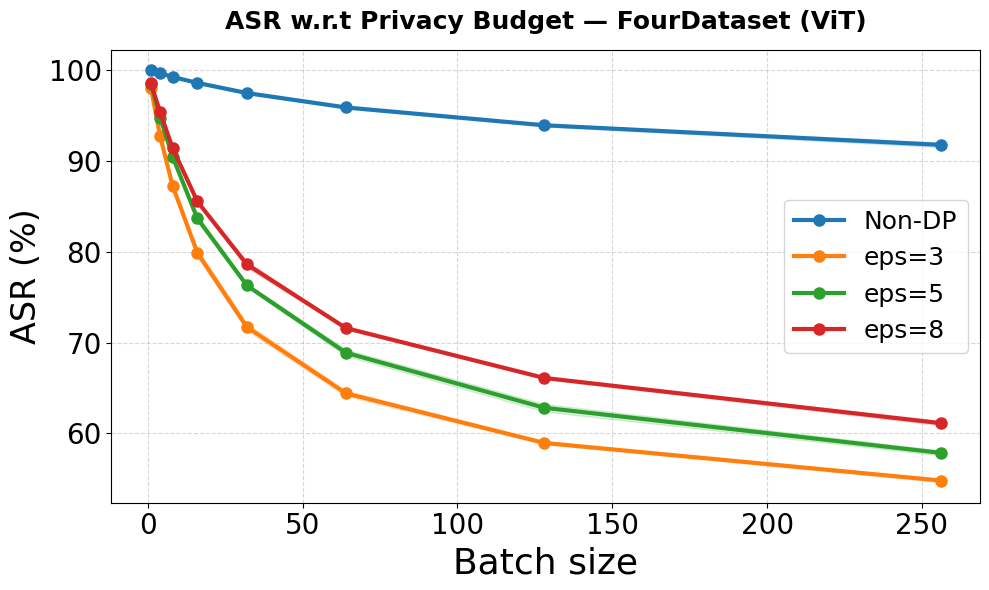

    Batch size Setting  ASR_mean   ASR_std  Adv_mean   Adv_std
0            1  Non-DP  99.99700  0.004472   99.9940  0.008944
1            1   eps=3  98.09400  0.015166   96.1880  0.030332
2            1   eps=5  98.51300  0.055745   97.0260  0.111490
3            1   eps=8  98.59900  0.062690   97.1980  0.125379
4            4  Non-DP  99.70000  0.049497   99.4000  0.098995
5            4   eps=3  92.74700  0.146825   85.4940  0.293649
6            4   eps=5  94.80400  0.109624   89.6080  0.219249
7            4   eps=8  95.37100  0.251928   90.7420  0.503855
8            8  Non-DP  99.28200  0.037683   98.5640  0.075366
9            8   eps=3  87.30300  0.216870   74.6060  0.433740
10           8   eps=5  90.50500  0.122219   81.0100  0.244438
11           8   eps=8  91.45200  0.296323   82.9040  0.592647
12          16  Non-DP  98.63000  0.095459   97.2600  0.190919
13          16   eps=3  79.90300  0.454898   59.8060  0.909797
14          16   eps=5  83.70300  0.342976   67.4060  0

In [7]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Files configuration
files = {
    "Non-DP": "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_stealth.txt",
    "eps=3": "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_eps3_stealth.txt",
    "eps=5": "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_eps5_stealth.txt",
    "eps=8": "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_eps8_stealth.txt",
}

pattern = re.compile(
    r"mia batch size:\s*(\d+).*?TPR:\s*([\d.]+)%.*?TNR:\s*([\d.]+)%.*?Advantage:\s*([\d.]+)%",
    re.DOTALL
)

rows = []

for setting, path in files.items():
    try:
        text = Path(path).read_text(errors="ignore")
        matches = pattern.findall(text)
        for bs, tpr, tnr, adv in matches:
            asr = (float(tpr) + float(tnr)) / 2.0
            rows.append((int(bs), setting, float(adv), asr))
    except FileNotFoundError:
        print(f"Warning: {path} not found.")

df = pd.DataFrame(rows, columns=["Batch size", "Setting", "Adv", "ASR"])
df = df[df["Batch size"] <= 256]

# Aggregate mean and std
agg = (
    df.groupby(["Batch size", "Setting"])
      .agg(
          ASR_mean=("ASR", "mean"),
          ASR_std=("ASR", "std"),
          Adv_mean=("Adv", "mean"),
          Adv_std=("Adv", "std"),
      )
      .reset_index()
      .sort_values("Batch size")
)

def plot_metric_with_fill(df, mean_col, std_col, ylabel, title, marker="o"):
    plt.figure(figsize=(10, 6))
    settings = ["Non-DP", "eps=3", "eps=5", "eps=8"]
    
    for setting in settings:
        sub = df[df["Setting"] == setting]
        if sub.empty:
            continue
            
        # Plot the main line
        line, = plt.plot(
            sub["Batch size"],
            sub[mean_col],
            marker=marker,
            linewidth=3,
            markersize=8,
            label=setting
        )
        
        # Fill standard deviation area
        plt.fill_between(
            sub["Batch size"],
            sub[mean_col] - sub[std_col],
            sub[mean_col] + sub[std_col],
            color=line.get_color(),
            alpha=0.15 # Adjust transparency for better overlap visibility
        )

    plt.xlabel("Batch size", fontsize=26)
    plt.ylabel(ylabel, fontsize=24)
    plt.title(title, fontsize=18, weight="bold", pad=15)
    plt.legend(fontsize=18, loc='best', frameon=True)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    plt.tight_layout()
    plt.show()

# Generate the plot
plot_metric_with_fill(
    agg,
    mean_col="ASR_mean",
    std_col="ASR_std",
    ylabel="ASR (%)",
    title="ASR w.r.t Privacy Budget — FourDataset (ViT)",
)

print(agg)

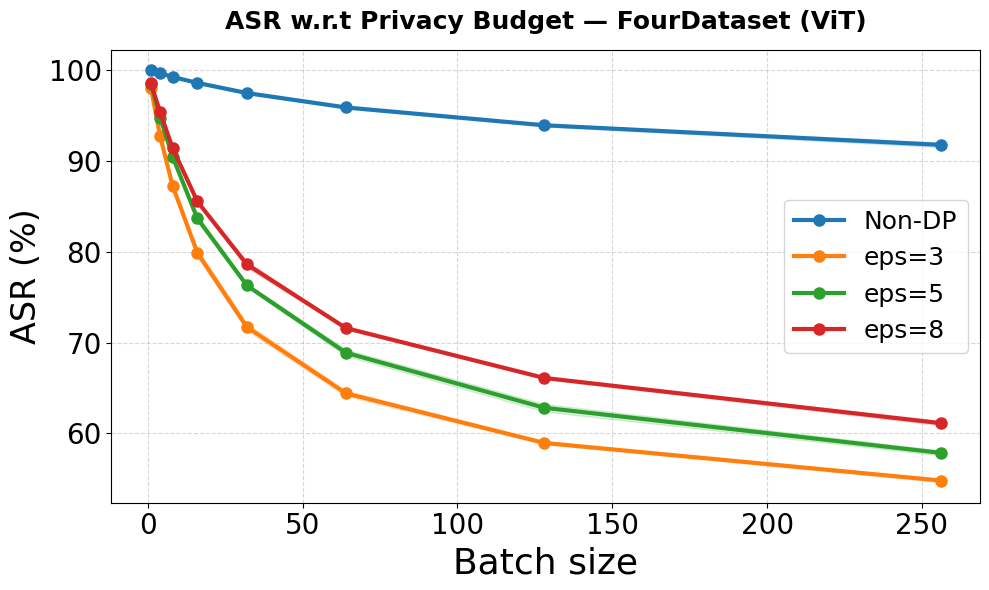

    Batch size Setting  ASR_mean   ASR_std  Adv_mean   Adv_std
0            1  Non-DP  99.99700  0.004472   99.9940  0.008944
1            1   eps=3  98.09400  0.015166   96.1880  0.030332
2            1   eps=5  98.51300  0.055745   97.0260  0.111490
3            1   eps=8  98.59900  0.062690   97.1980  0.125379
4            4  Non-DP  99.70000  0.049497   99.4000  0.098995
5            4   eps=3  92.74700  0.146825   85.4940  0.293649
6            4   eps=5  94.80400  0.109624   89.6080  0.219249
7            4   eps=8  95.37100  0.251928   90.7420  0.503855
8            8  Non-DP  99.28200  0.037683   98.5640  0.075366
9            8   eps=3  87.30300  0.216870   74.6060  0.433740
10           8   eps=5  90.50500  0.122219   81.0100  0.244438
11           8   eps=8  91.45200  0.296323   82.9040  0.592647
12          16  Non-DP  98.63000  0.095459   97.2600  0.190919
13          16   eps=3  79.90300  0.454898   59.8060  0.909797
14          16   eps=5  83.70300  0.342976   67.4060  0

In [6]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Files configuration
files = {
    "Non-DP": "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_stealth.txt",
    "eps=3": "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_eps3_stealth.txt",
    "eps=5": "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_eps5_stealth.txt",
    "eps=8": "/home/quannm/code/icml_promptmia/result_log/fourdataset_vit_eps8_stealth.txt",
}

pattern = re.compile(
    r"mia batch size:\s*(\d+).*?TPR:\s*([\d.]+)%.*?TNR:\s*([\d.]+)%.*?Advantage:\s*([\d.]+)%",
    re.DOTALL
)

rows = []

for setting, path in files.items():
    try:
        text = Path(path).read_text(errors="ignore")
        matches = pattern.findall(text)
        for bs, tpr, tnr, adv in matches:
            asr = (float(tpr) + float(tnr)) / 2.0
            rows.append((int(bs), setting, float(adv), asr))
    except FileNotFoundError:
        print(f"Warning: {path} not found.")

df = pd.DataFrame(rows, columns=["Batch size", "Setting", "Adv", "ASR"])
df = df[df["Batch size"] <= 256]

# Aggregate mean and std
agg = (
    df.groupby(["Batch size", "Setting"])
      .agg(
          ASR_mean=("ASR", "mean"),
          ASR_std=("ASR", "std"),
          Adv_mean=("Adv", "mean"),
          Adv_std=("Adv", "std"),
      )
      .reset_index()
      .sort_values("Batch size")
)

def plot_metric_with_fill(df, mean_col, std_col, ylabel, title, marker="o"):
    plt.figure(figsize=(10, 6))
    settings = ["Non-DP", "eps=3", "eps=5", "eps=8"]
    
    for setting in settings:
        sub = df[df["Setting"] == setting]
        if sub.empty:
            continue
            
        # Plot the main line
        line, = plt.plot(
            sub["Batch size"],
            sub[mean_col],
            marker=marker,
            linewidth=3,
            markersize=8,
            label=setting
        )
        
        # Fill standard deviation area
        plt.fill_between(
            sub["Batch size"],
            sub[mean_col] - sub[std_col],
            sub[mean_col] + sub[std_col],
            color=line.get_color(),
            alpha=0.15 # Adjust transparency for better overlap visibility
        )

    plt.xlabel("Batch size", fontsize=26)
    plt.ylabel(ylabel, fontsize=24)
    plt.title(title, fontsize=18, weight="bold", pad=15)
    plt.legend(fontsize=18, loc='best', frameon=True)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=20)
    plt.tight_layout()
    plt.show()

# Generate the plot
plot_metric_with_fill(
    agg,
    mean_col="ASR_mean",
    std_col="ASR_std",
    ylabel="ASR (%)",
    title="ASR w.r.t Privacy Budget — FourDataset (ViT)",
)

print(agg)

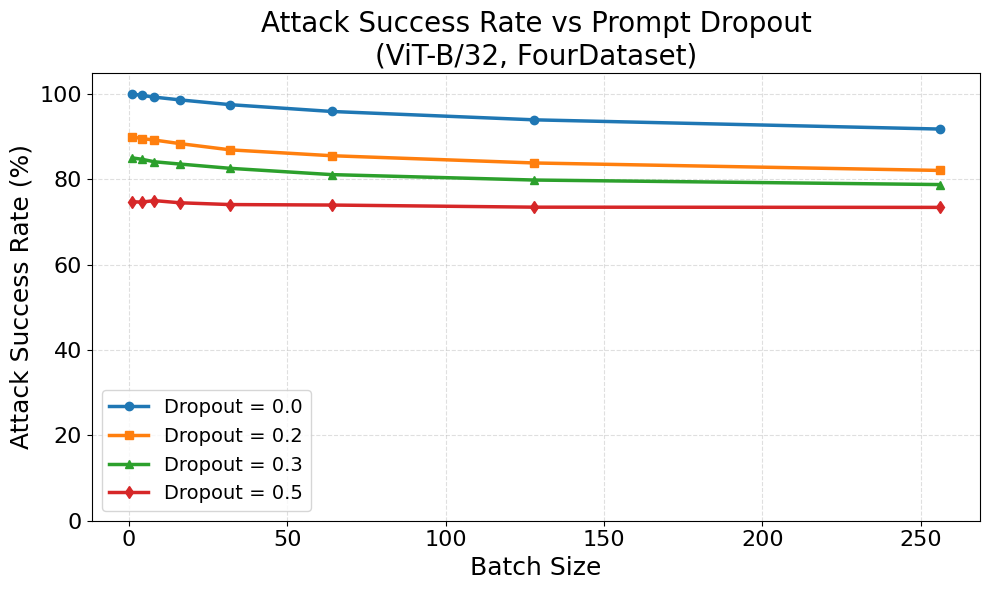

In [19]:
import matplotlib.pyplot as plt

asr_no_dropout = [100.00, 99.70, 99.28, 98.64, 97.51, 95.92, 93.96, 91.80]
asr_dropout_02 = [89.97,89.57,89.22,88.39,86.92,85.55,83.85,82.10]
asr_dropout_03 = [85.04,84.72,84.13,83.60,82.59,81.12,79.85,78.79]
asr_dropout_05 = [74.76,74.68,75.03,74.52,74.10,73.99,73.49,73.44]

batch_sizes = [1, 4, 8, 16, 32, 64, 128, 256]

colors = {
    '0.0': '#1f77b4',
    '0.2': '#ff7f0e',
    '0.3': '#2ca02c',
    '0.5': '#d62728',
}

plt.figure(figsize=(10, 6))

plt.plot(batch_sizes, asr_no_dropout, marker='o', linewidth=2.5,
         label='Dropout = 0.0', color=colors['0.0'])
plt.plot(batch_sizes, asr_dropout_02, marker='s', linewidth=2.5,
         label='Dropout = 0.2', color=colors['0.2'])
plt.plot(batch_sizes, asr_dropout_03, marker='^', linewidth=2.5,
         label='Dropout = 0.3', color=colors['0.3'])
plt.plot(batch_sizes, asr_dropout_05, marker='d', linewidth=2.5,
         label='Dropout = 0.5', color=colors['0.5'])

plt.ylim(0, 105)
plt.xlabel('Batch Size', fontsize=18)
plt.ylabel('Attack Success Rate (%)', fontsize=18)
plt.title('Attack Success Rate vs Prompt Dropout\n(ViT-B/32, FourDataset)', fontsize=20)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(fontsize=14)

plt.tight_layout()
plt.show()


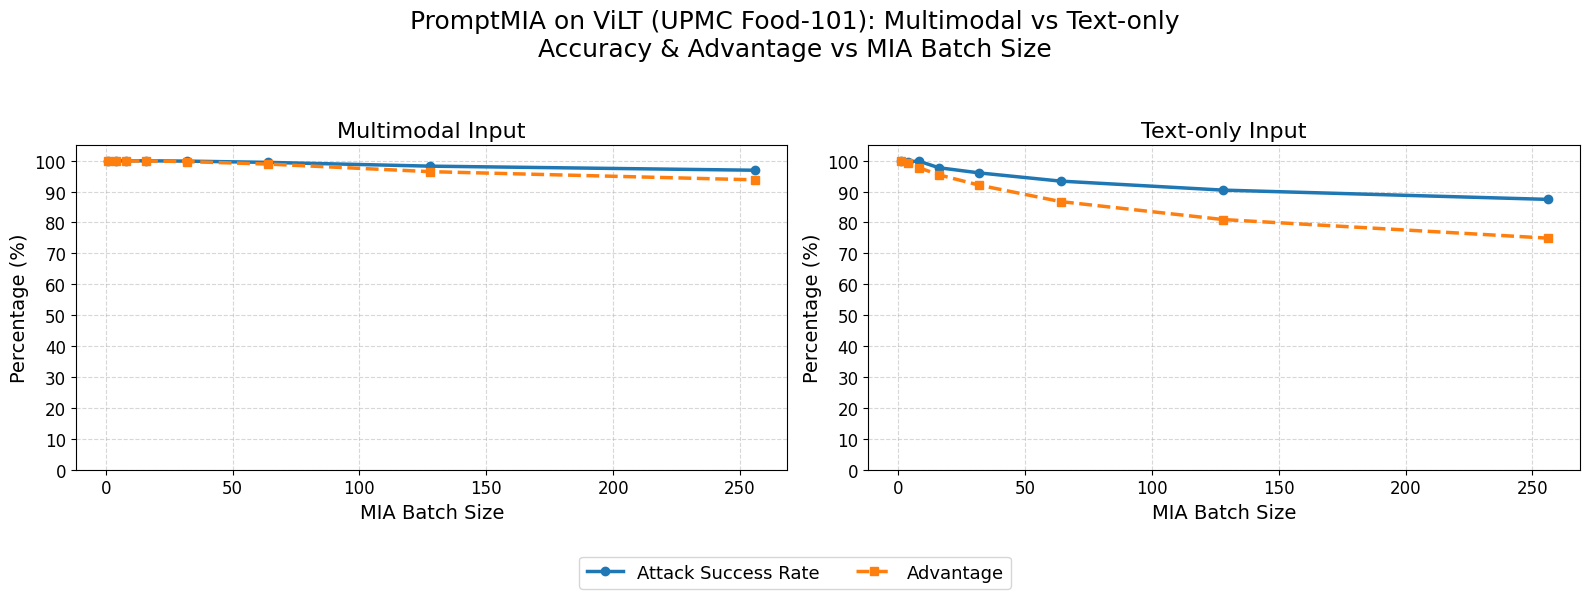

In [20]:
import matplotlib.pyplot as plt

# -------- Data (unchanged) --------
batch_sizes_mm = [1, 4, 8, 16, 32, 64, 128, 256]
acc_mm = [
    99.99,99.99,99.95,99.94,99.84,99.43,98.21,96.89
]
adv_mm = [100.00, 100, 99.9, 99.9, 99.69, 98.88, 96.43, 93.78]

batch_sizes_txt = [1, 4, 8, 16, 32, 64, 128, 256]
acc_txt = [
    99.89,99.64,99.87,97.70,96.02,93.37, 90.46,87.46
]
adv_txt = [99.80, 99.29, 97.76, 95.41, 92.05, 86.75, 80.94, 74.92]

# -------- Larger Figure + Plotting --------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

configs = [
    ("Multimodal Input", batch_sizes_mm, acc_mm, adv_mm),
    ("Text-only Input", batch_sizes_txt, acc_txt, adv_txt),
]

handles, labels = None, None

for ax, (title, bs, acc, adv) in zip(axes.flat, configs):
    l1, = ax.plot(
        bs, acc,
        marker="o",
        linestyle="-",
        linewidth=2.5,       # ← thicker line
        label="Attack Success Rate"
    )
    l2, = ax.plot(
        bs, adv,
        marker="s",
        linestyle="--",
        linewidth=2.5,       # ← thicker line
        label="Advantage"
    )

    ax.set_title(title, fontsize=16)
    ax.set_xlabel("MIA Batch Size", fontsize=14)
    ax.set_ylabel("Percentage (%)", fontsize=14)

    ax.set_ylim(0, 105)
    ax.set_yticks(range(0, 101, 10))

    ax.tick_params(axis="both", labelsize=12)
    ax.grid(True, linestyle="--", alpha=0.5)

    if handles is None and labels is None:
        handles, labels = ax.get_legend_handles_labels()

# Shared legend
fig.legend(handles, labels, loc="lower center", fontsize=13, ncol=2)

plt.suptitle(
    "PromptMIA on ViLT (UPMC Food-101): Multimodal vs Text-only\nAccuracy & Advantage vs MIA Batch Size",
    fontsize=18
)

plt.tight_layout(rect=[0, 0.10, 1, 0.93])
plt.show()
